# Is trial-mode entropy a consequence of the mean behaviour LD1 captures?

Mode-use entropy tracks LD1 across mice (`trial_mode_entropy.ipynb`; ρ ≈ −0.37, more trial modes used at the low-LD1 end). LD1 is a linear read-out of mean syllable usage, and the modes are built from the same syllables. So the entropy result could just follow from how **average** mode usage shifts along LD1, and add nothing.

**Test** (`mode_entropy_from_ld1.py`). Predict each mouse's mode-usage profile from its LD1 alone (leave that mouse out), and take the entropy of the predicted profile with the same sample size and estimator as the observed one. If the mean shift is the whole story:
1. the predicted entropy reproduces the observed entropy–LD1 slope (ratio ≈ 1), and
2. the residual (observed − predicted) is flat along LD1.

Two models for profile vs LD1: `linear` (usage of each mode linear in LD1) and `log` (log usage linear in LD1, always positive). As a generous version, LD1–3 together.

**Decomposition.** A mouse's mean per-session entropy is lower than the entropy of its pooled profile when its sessions use *different* modes: H_modes = H_pooled − spread. `spread` is the between-session part, which no mean profile can capture.

Mice are the unit, Spearman. The 17-mode fit (`trial_modes_8_k_10_bin_syllables_02-10-2026`), LDA `mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026`.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'trial_modes.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
PI = REPO / 'paper-individuality'
sys.path.insert(0, str(PI)); sys.path.insert(0, str(PI / '3_trial_modes'))
import paper_style as ps
import mode_entropy_from_ld1 as me
ps.use('paper')
pd.set_option('display.width', 160)

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Parameters

In [2]:
MODELS = ['linear', 'log']
COVARIATE_SETS = {'LD1': ['lda_1'], 'LD1-3': ['lda_1', 'lda_2', 'lda_3']}
N_BOOT = 1000      # bootstrap over mice for the slope ratio

## Data: usage profiles and observed entropies

In [3]:
U, meta, N_TRIALS, trials = me.load_usage()
K = U.shape[1]
H_sess = me.observed_entropy(trials, K, N_TRIALS)
S = meta.join(H_sess)
M = S.groupby('mouse_name').agg(H_modes=('H_sess', 'mean'), lda_1=('lda_1', 'mean'), lda_2=('lda_2', 'mean'),
                                lda_3=('lda_3', 'mean'), lab=('lab', 'first'), n_sessions=('H_sess', 'size'))
P = U.join(meta['mouse_name']).groupby('mouse_name').mean().loc[M.index].to_numpy()
rng = np.random.default_rng(me.SEED)
M['H_pooled'] = [me.expected_entropy(p, K, N_TRIALS, rng=rng) for p in P]
M['spread'] = M['H_pooled'] - M['H_modes']
print(f'{len(S)} sessions, {len(M)} mice, {K} modes, {N_TRIALS} trials per subsample')
rows = []
for c in ['H_modes', 'H_pooled', 'spread']:
    r = spearmanr(M['lda_1'], M[c])
    lc = M[['lda_1', c]] - M.groupby('lab')[['lda_1', c]].transform('mean')
    rl = spearmanr(lc['lda_1'], lc[c])
    rows.append(dict(measure=c, mean=M[c].mean(), rho=r.statistic, p=r.pvalue, rho_lab_centred=rl.statistic, p_lab_centred=rl.pvalue))
print(pd.DataFrame(rows).set_index('measure').round(3).to_string())

260 sessions, 56 mice, 17 modes, 372 trials per subsample
           mean    rho      p  rho_lab_centred  p_lab_centred
measure                                                      
H_modes   0.835 -0.370  0.005           -0.483          0.000
H_pooled  0.868 -0.226  0.095           -0.266          0.047
spread    0.033  0.232  0.085            0.457          0.000


### Which modes move along LD1?

Mouse-level Spearman of each mode's usage with LD1 (FDR over modes). Many modes shift, so a mean-shift explanation is plausible a priori.

In [4]:
rr = [spearmanr(M['lda_1'], P[:, j]) for j in range(K)]
modes_ld = pd.DataFrame({'mode': U.columns.astype(int), 'mean_use': P.mean(0), 'rho': [r.statistic for r in rr],
                         'q': multipletests([r.pvalue for r in rr], method='fdr_bh')[1]}).sort_values('mean_use', ascending=False)
print(modes_ld.round(3).to_string(index=False))
print(f"\n{(modes_ld['q'] < 0.05).sum()} of {K} modes shift with LD1 (q < .05)")

 mode  mean_use    rho     q
    1     0.124  0.428 0.003
    2     0.102 -0.396 0.006
    7     0.091  0.273 0.059
    3     0.082 -0.204 0.172
    4     0.078 -0.154 0.314
    8     0.068 -0.460 0.002
   10     0.062  0.098 0.522
    5     0.059  0.094 0.522
    6     0.052 -0.436 0.003
   12     0.048 -0.541 0.000
   11     0.045 -0.401 0.006
    9     0.044 -0.317 0.029
   15     0.043  0.311 0.031
   13     0.034 -0.043 0.750
   14     0.028 -0.319 0.029
   16     0.025  0.543 0.000
   17     0.015  0.374 0.010

11 of 17 modes shift with LD1 (q < .05)


## The test: entropy of the profile predicted from LD1

`R2` is how much of the across-mouse variance in usage profiles the covariates predict (held out). `slope ratio` = slope of predicted entropy on LD1 / slope of observed entropy on LD1, with a bootstrap 95 % CI over mice (refitting the held-out predictions in each resample).

In [5]:
x = M['lda_1'].to_numpy()
slope = lambda a, b: np.polyfit(a, b, 1)[0]
PRED, rows = {}, []
for name, cols in COVARIATE_SETS.items():
    for model in MODELS:
        P_hat = me.predict_profiles(P, M[cols].to_numpy(), model)
        H_hat = np.array([me.expected_entropy(p, K, N_TRIALS, rng=rng) for p in P_hat])
        PRED[(name, model)] = H_hat
        res = M['H_modes'].to_numpy() - H_hat
        # bootstrap the slope ratio over mice (the prediction is refitted inside each resample)
        brng, ratios = np.random.default_rng(1), []
        for _ in range(N_BOOT):
            idx = brng.integers(0, len(M), len(M))
            Pb = me.predict_profiles(P[idx], M[cols].to_numpy()[idx], model)
            # predicted entropy without the multinomial simulation (fast): plug-in of the profile minus the
            # Miller-Madow bias, which is what the simulation estimates
            Hb = np.array([me.norm_entropy(p, K) for p in Pb]) - (K - 1) / (2 * N_TRIALS * np.log(K))
            ratios.append(slope(x[idx], Hb) / slope(x[idx], M['H_modes'].to_numpy()[idx]))
        lo, hi = np.percentile(ratios, [2.5, 97.5])
        r_res = spearmanr(x, res)
        rows.append(dict(covariates=name, model=model, profile_R2=me.profile_r2(P, P_hat),
                         rho_pred_LD1=spearmanr(x, H_hat).statistic, rho_obs_pred=spearmanr(M['H_modes'], H_hat).statistic,
                         slope_ratio=slope(x, H_hat) / slope(x, M['H_modes']), ratio_lo=lo, ratio_hi=hi,
                         rho_resid_LD1=r_res.statistic, p_resid_LD1=r_res.pvalue))
TEST = pd.DataFrame(rows).set_index(['covariates', 'model'])
print(TEST.round(3).to_string())

                   profile_R2  rho_pred_LD1  rho_obs_pred  slope_ratio  ratio_lo  ratio_hi  rho_resid_LD1  p_resid_LD1
covariates model                                                                                                      
LD1        linear       0.056        -0.085         0.103        0.212    -0.463     0.688         -0.324        0.015
           log          0.032        -0.377         0.169        0.319    -0.271     0.814         -0.260        0.053
LD1-3      linear       0.143        -0.213         0.330        0.291    -0.202     0.695         -0.285        0.033
           log          0.101        -0.164         0.224        0.428    -0.022     1.199         -0.249        0.064


## Figure

(a) Observed entropy vs LD1 (mice), with the entropy predicted from LD1 alone (log-linear model) as open circles: the prediction is much flatter. (b) The residual (observed − predicted) vs LD1. (c) The decomposition: entropy of the pooled profile and between-session spread vs LD1.

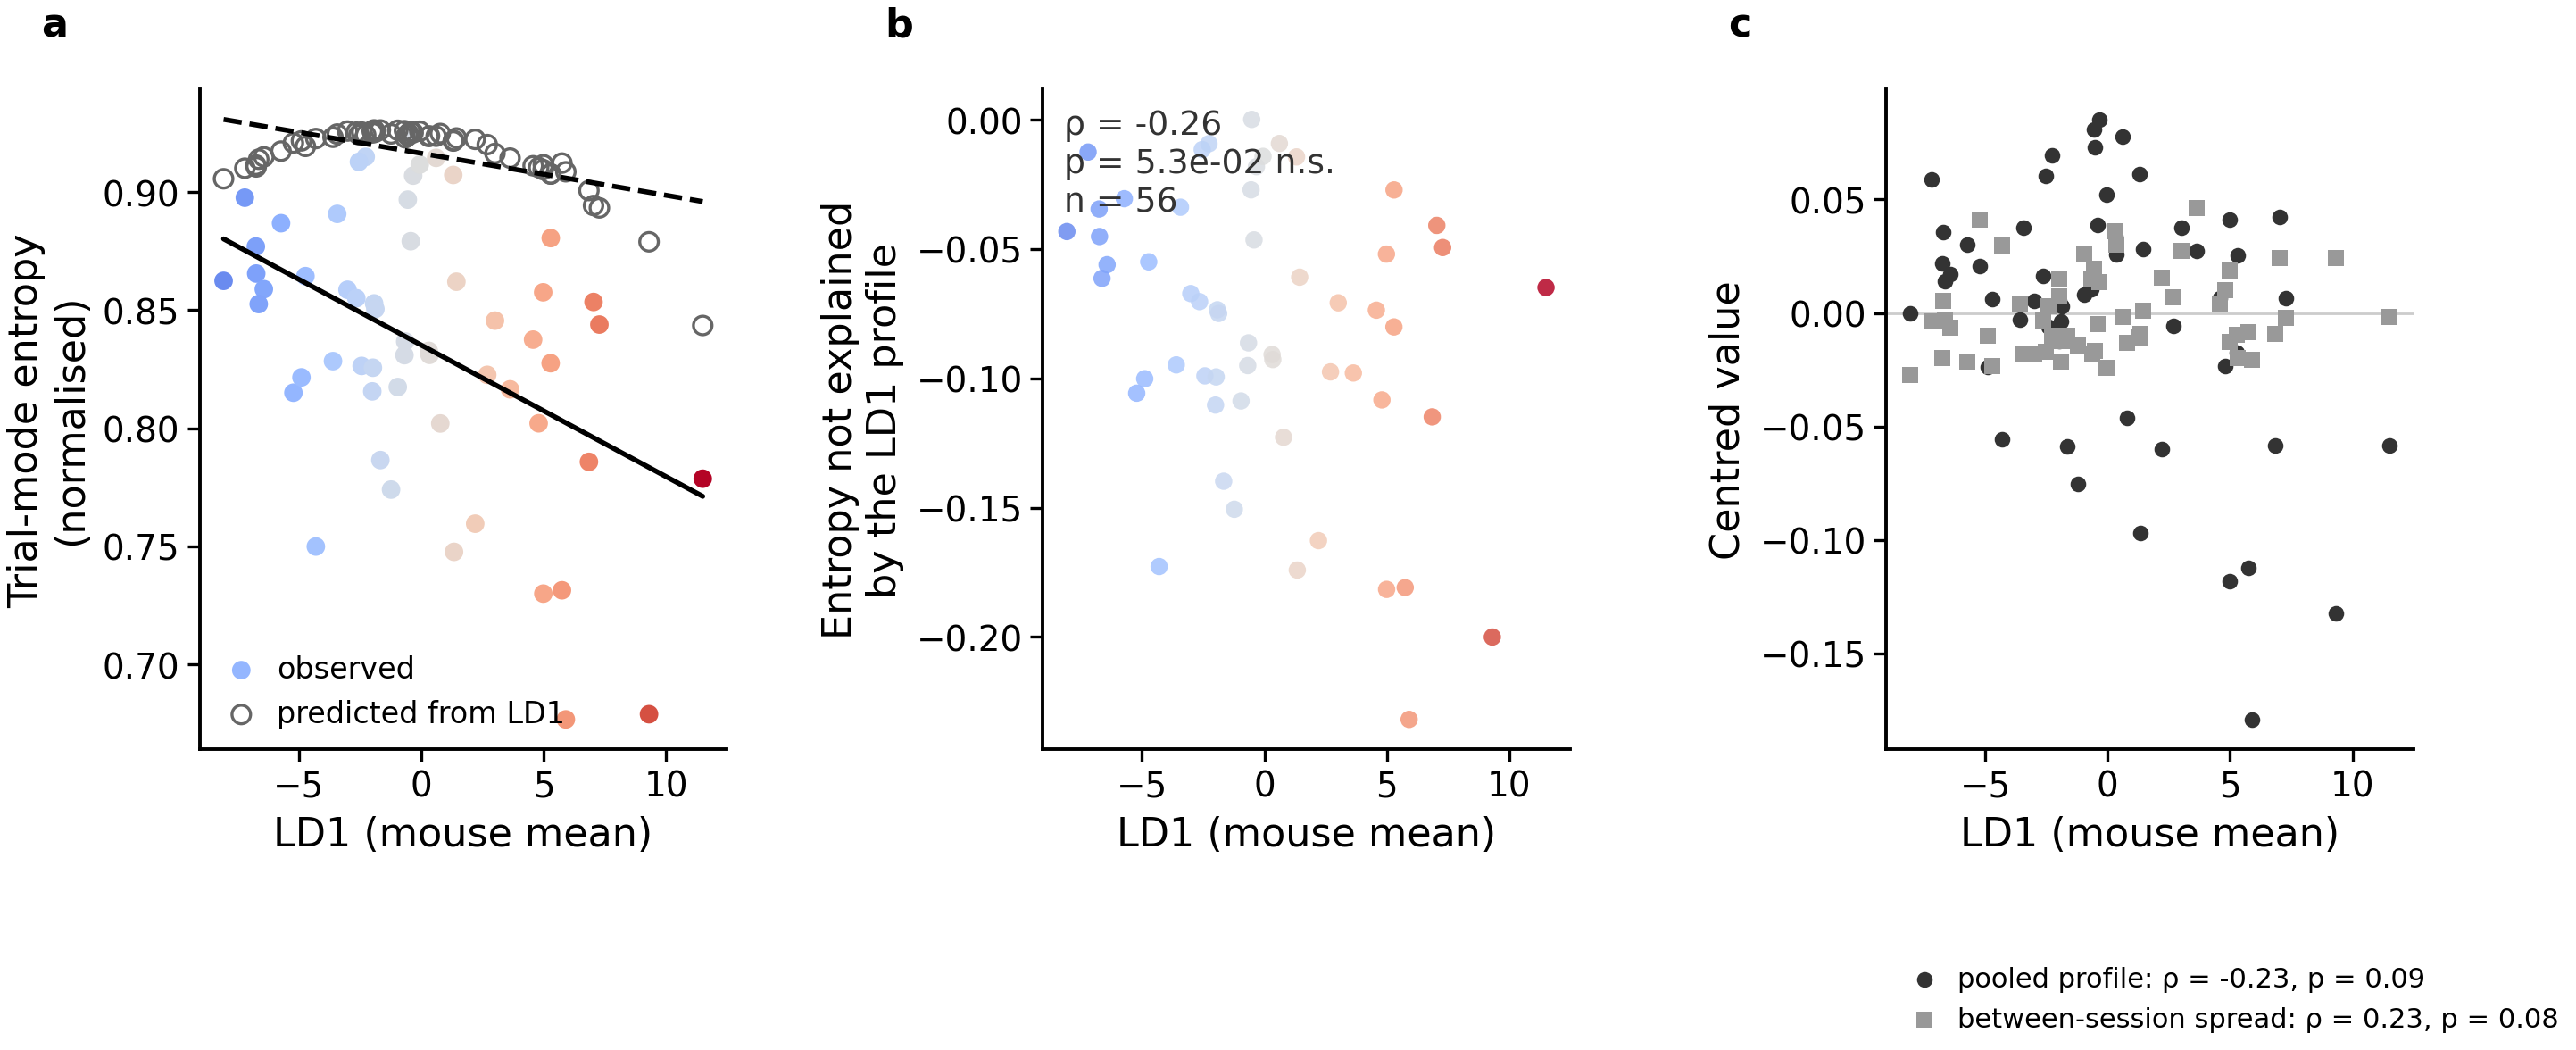

In [6]:
H_hat = PRED[('LD1', 'log')]
col = ps.ld1_colors(x)
fig, axes = plt.subplots(1, 3, figsize=(8, 2.4), gridspec_kw=dict(wspace=0.6))
ax = axes[0]
ax.scatter(x, M['H_modes'], c=col, s=14, lw=0, label='observed')
ax.scatter(x, H_hat, facecolor='none', edgecolor='0.4', s=14, lw=0.6, label='predicted from LD1')
for y, ls in [(M['H_modes'], '-'), (H_hat, '--')]:
    b = np.polyfit(x, y, 1); xs = np.array([x.min(), x.max()]); ax.plot(xs, b[0] * xs + b[1], color='k', ls=ls, lw=1)
ax.set_xlabel('LD1 (mouse mean)'); ax.set_ylabel('Trial-mode entropy\n(normalised)'); ax.legend(frameon=False, fontsize=6)
ps.corr_panel(axes[1], M['lda_1'], M['H_modes'] - H_hat, color=col, method='spearman',
              xlabel='LD1 (mouse mean)', ylabel='Entropy not explained\nby the LD1 profile')
ax = axes[2]
for c, mk in [('H_pooled', 'o'), ('spread', 's')]:
    r = spearmanr(x, M[c])
    ax.scatter(x, M[c] - M[c].mean(), s=10, marker=mk, color='0.2' if c == 'H_pooled' else '0.6', lw=0,
               label=f"{'pooled profile' if c == 'H_pooled' else 'between-session spread'}: ρ = {r.statistic:.2f}, p = {r.pvalue:.2f}")
ax.axhline(0, color='0.8', lw=0.5, zorder=0)
ax.set_xlabel('LD1 (mouse mean)'); ax.set_ylabel('Centred value'); ax.legend(frameon=False, fontsize=5.5, loc='upper left', bbox_to_anchor=(0, -0.3))
for a, l in zip(axes, 'abc'):
    a.text(-0.3, 1.08, l, transform=a.transAxes, fontweight='bold')
plt.show()

## Summary

1. **The mean shift along LD1 explains only a minority of the entropy effect.** 11 of 17 modes shift with LD1, but LD1 predicts only 3–6 % of the across-mouse variance in usage profiles (held out; 10–14 % with LD1–3). The entropy of the profile predicted from LD1 reproduces 21–32 % of the observed entropy–LD1 slope (43 % with LD1–3). The residual (observed − predicted) still tracks LD1: ρ = −0.25 to −0.32, p = .015–.064.
2. **But this can't rule the mean-shift account out.** The bootstrap CIs on the slope ratio are wide (upper ends 0.7–1.2), and the residual effect is borderline. So the data neither show that entropy is just the mean shift nor firmly exclude it. The point estimate says the mean shift is about a third.
3. **Where the rest sits: consistency across sessions.** The mean per-session entropy is the entropy of the mouse's pooled profile minus a between-session spread term. The pooled-profile entropy tracks LD1 only weakly (ρ = −0.23, p = .09; lab-centred −0.27, p = .047). The spread tracks it in the other direction (+0.23, p = .09), and strongly within labs (+0.46, p < .001). So, compared with other mice in the same lab, high-LD1 mice concentrate each session on fewer modes, but on different modes in different sessions. That is a property of sessions, which a mean profile (and so LD1, a mean-usage read-out) can't express. Mice with more sessions have more spread (ρ = 0.39), but session count doesn't track LD1 (−0.19, n.s.). Controlling for it strengthens the spread effect (+0.31, p = .019; lab-centred +0.48, p < .001). Every mouse has ≥ 3 sessions.
4. **Caveat for panel a.** The predicted entropies sit above all observed ones. A profile predicted from LD1 averages over mice, so it is more even than any single mouse's (Jensen). Only the slopes are compared, not the levels.

**For the text:** "entropy is just a consequence of LD1's mean behaviour" is not supported as stated. Part of it is (≈ ⅓ of the slope); the rest is session-to-session concentration, which is lab-robust. Note that the lab-centred entropy effect (−0.48) is stronger than the raw one, and the spread term is where that strength comes from.
